# Adversarial Search: Solving Tic-Tac-Toe with Pure Monte Carlo Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Pure Monte Carlo search

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

%precision 3

'%.3f'

# Pure Monte Carlo Search

See AIMA page 161ff. 

We implement a extremely simplified version.

For the current state: 
1. Simulate $N$ random playouts for each possible action and 
2. pick the action with the highest average utility.

__Important note:__ we use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with
1. a good __playout policy__ (e.g., learned by self-play) and 
2. a __selection strategy__ (e.g., UCB1).

## Simulate playouts

### [Bài 5] Cách hoạt động của `playout()` và `playouts()`

- **`playout(state, action, player)`**: đi nước `action` cho `player`, sau đó **hai bên chọn ngẫu nhiên** một ô trống ở mỗi lượt
  cho tới khi ván kết thúc, rồi trả **utility theo góc nhìn `player`**: +1 thắng, 0 hòa, −1 thua. Một playout là một ván giả lập.
- **`playouts(board, action, player, N)`**: lặp `playout` N lần cho cùng một nước, trả danh sách N kết quả. Trung bình các kết quả
  là **ước lượng giá trị** của nước đó, giả định từ đó về sau cả hai bên đều chơi ngẫu nhiên.

In [3]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: return(u)
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


# Playout for action 0 (top-left corner)
board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

0
1
1
1
1


In [4]:
def playouts(board, action, player = 'x', N = 100):
    """Perform N playouts following the given action for the given board."""
    return [ playout(board, action, player) for i in range(N) ]

u = playouts(board, 0)
print("Playout results:", u)

print(f"mean utility: {np.mean(u)}")

p_win = sum(np.array(u) == +1)/len(u)
p_loss = sum(np.array(u) == -1)/len(u)
p_draw = sum(np.array(u) == 0)/len(u)
print(f"win probability: {p_win}")
print(f"loss probability: {p_loss}")
print(f"draw probability: {p_draw}")

Playout results: [1, 0, 1, 1, 1, -1, 1, 1, 1, 1, 1, 1, -1, 0, 0, 0, 1, -1, 1, 1, 1, -1, 1, 0, 1, 0, 1, 1, 0, 1, -1, 1, -1, 1, 0, -1, 1, 1, 1, 1, 1, 1, -1, 1, 1, 0, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, -1, 1, 1, 1, 0, -1, 1, 1, -1, 1, 1, 1, -1, -1, 1, 1, 0, 0, -1, 0, -1, 0, -1, 1, -1, -1, 1, 1, 1, 1, -1, 1, -1, 1, 1, 1, 1, 1, -1, 1, -1]
mean utility: 0.38
win probability: 0.61
loss probability: 0.23
draw probability: 0.16


**[Bài 5] Nhận xét `playout` / `playouts`.** Hai ô trên chạy playout sau khi x đi ô 0 trên bàn trống. Mỗi playout cho một kết quả
khác nhau (thắng, hòa hoặc thua) vì phần còn lại của ván là ngẫu nhiên, nên một lần chạy playout đơn lẻ chưa đủ cơ sở đánh giá; cần lấy
**trung bình qua nhiều playout**. Kết quả thắng thường chiếm phần lớn vì x đi trước và có thêm một quân (đúng như ghi chú của đề).
Hai ô này không cố định seed nên con số cụ thể thay đổi mỗi lần chạy.

__Note:__ This shows that the player who goes first has a significant advantage in __pure random play.__ Real players do not play randomly, a better playout policy would be good.

## Pure Monte Carlo Search

### [Bài 5] Cách hoạt động của `pmcs()`

`pmcs(board, N, player)`:
1. Lấy các nước hợp lệ `acts`, **chia đều** ngân sách: mỗi nước nhận $n = \lfloor N / |acts| \rfloor$ playout. Ví dụ N = 10 với
   5 nước thì mỗi nước 2 playout; N = 10 trên bàn trống (9 nước) thì mỗi nước chỉ **1** playout (dùng 9 trong 10 playout).
2. Với mỗi nước, chạy `playouts` và lấy **trung bình utility**.
3. Chọn nước có trung bình **lớn nhất**. Khi nhiều nước bằng nhau, `max` lấy nước đứng trước trong danh sách (chỉ số ô nhỏ hơn).

Khác với Minimax, PMCS **không xây cây** và **không cần hàm đánh giá heuristic**: giá trị của nước được ước lượng bằng mô phỏng.
Đổi lại, PMCS giả định đối thủ chơi ngẫu nhiên, và chia đều playout kể cả cho những nước đã rõ là kém.

In [5]:
import math

DEBUG = 1


def pmcs(board, N = 100, player = 'x'):
    """Pure Monte Carlo Search. Returns the action that has the largest average utility.
    The N playouts are evenly divided between the possible actions."""
    global DEBUG
    
    acts = actions(board)
    n = math.floor(N/len(acts))
    if DEBUG >= 1: print(f"Actions: {acts} ({N} total playouts = {n} playouts per action)")
    
    ps = { i : np.mean(playouts(board, i, player, N = n)) for i in acts }
    if DEBUG >= 1: display(ps)
        
    action = max(ps, key=ps.get)
    return action

board = empty_board()
display(board)
%time print(pmcs(board))

print()
print("10000 playouts give a better utility estimate.")
%time print(pmcs(board, N = 10000))

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (100 total playouts = 11 playouts per action)


{0: 0.182,
 1: 0.455,
 2: 0.182,
 3: 0.455,
 4: 0.909,
 5: 0.273,
 6: 0.455,
 7: 0.091,
 8: 0.273}

4
CPU times: total: 15.6 ms
Wall time: 24.5 ms

10000 playouts give a better utility estimate.
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10000 total playouts = 1111 playouts per action)


{0: 0.338,
 1: 0.164,
 2: 0.314,
 3: 0.187,
 4: 0.488,
 5: 0.211,
 6: 0.338,
 7: 0.148,
 8: 0.401}

4
CPU times: total: 2.08 s
Wall time: 2.12 s


Looks like the center and the corners are a lot better.

**[Bài 5] Nhận xét bàn trống.** Với 10.000 playout (khoảng 1.111 playout mỗi nước), ước lượng khá ổn định: **ô giữa 4 cao nhất
(khoảng 0,5)**, các **góc** khoảng 0,3–0,4, các **cạnh** thấp nhất (khoảng 0,2), nên PMCS chọn ô 4. Đây là giá trị khi hai bên chơi
ngẫu nhiên; theo Minimax mọi nước đầu đều hòa (giá trị 0). Với 100 playout (11 playout mỗi nước), các ước lượng còn dao động mạnh,
nên nước được chọn có thể thay đổi giữa các lần chạy.

## Some Tests

### x is about to win (play 8)


Board:


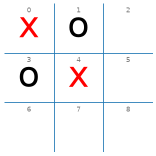


Actions: [2, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{2: 0.750, 5: 0.700, 6: 0.750, 7: 0.700, 8: 1.000}

8

CPU times: total: 15.6 ms
Wall time: 14.4 ms


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### o is about to win

Board:


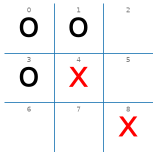


Actions: [2, 5, 6, 7] (100 total playouts = 25 playouts per action)


{2: -0.120, 5: -0.760, 6: 0.440, 7: -0.840}

6

CPU times: total: 0 ns
Wall time: 7.94 ms

Actions: [2, 5, 6, 7] (1000 total playouts = 250 playouts per action)


{2: 0.016, 5: -0.688, 6: -0.104, 7: -0.648}

2

CPU times: total: 62.5 ms
Wall time: 58.9 ms


In [7]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

print()
%time display(pmcs(board, N = 1000))

### x can draw if it chooses 7

Board:


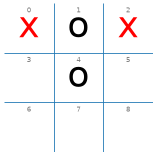


Actions: [3, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{3: 0.050, 5: -0.050, 6: -0.600, 7: 0.300, 8: -0.250}

7

CPU times: total: 0 ns
Wall time: 13.1 ms


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### Empty board: Only a draw an be guaranteed

Board:


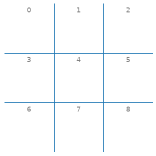


Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (5000 total playouts = 555 playouts per action)


{0: 0.351,
 1: 0.148,
 2: 0.357,
 3: 0.178,
 4: 0.573,
 5: 0.195,
 6: 0.375,
 7: 0.169,
 8: 0.344}

4

CPU times: total: 1.06 s
Wall time: 1.09 s


In [9]:
board = empty_board() 

print("Board:")
show_board(board)

print()
%time display(pmcs(board, N = 5000))

### A bad situation

Board:


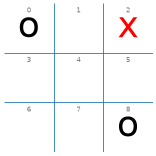


Actions: [1, 3, 4, 5, 6, 7] (100 total playouts = 16 playouts per action)


{1: -0.125, 3: -0.625, 4: 0.250, 5: -0.625, 6: 0.250, 7: -0.688}

4

CPU times: total: 15.6 ms
Wall time: 14.9 ms


In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

**[Bài 5] Nhận xét các test gốc.** Mỗi ô test ở trên chỉ gọi `pmcs` **một lần** và không cố định seed, nên nước được chọn có thể
khác giữa các lần chạy và chưa đủ để đánh giá độ ổn định. Vì vậy bảng dưới chạy lại cả 5 trạng thái với N = 10, 100, 1000,
mỗi cấu hình 50 lần và cố định seed.

## [Bài 5] `pmcs` với N = 10, 100, 1000 trên các trạng thái test

Mỗi trạng thái (x đến lượt) chạy `pmcs` với N = 1000 trước (lâu nhất), rồi N = 100 và N = 10, mỗi cấu hình **50 lần** (seed 42).
Để chấm, mỗi nước được tính giá trị Minimax chính xác bằng cách duyệt hết cây (hàm `exact_value` chỉ dùng để chấm, không phải tác tử):
- **Nước tối ưu (Minimax):** các nước có giá trị Minimax lớn nhất.
- **Nước mong đợi:** thắng ngay nếu có; nếu không thì chặn đe dọa thắng ngay của o. Bàn trống không có nước mong đợi riêng.
- **Số nước khác nhau** trong 50 lần: càng ít thì quyết định càng ổn định.

In [11]:
# [Bài 5] pmcs với N = 1000, 100, 10 trên 5 trạng thái test, mỗi cấu hình gọi 50 lần (seed 42).
# Chạy N = 1000 trước vì lâu nhất. Đáp án chấm bằng Minimax duyệt hết cây (chỉ dùng để chấm, không phải tác tử).
import time
from collections import Counter
from functools import lru_cache
import pandas as pd

@lru_cache(maxsize=None)
def exact_value(key, to_move, me):
    """Giá trị Minimax chính xác của bàn `key` (chuỗi 9 ký tự) theo góc nhìn `me`."""
    board = list(key)
    value = utility(board, me)
    if value is not None:
        return value
    values = [exact_value(''.join(result(board, to_move, a)), other(to_move), me) for a in actions(board)]
    return max(values) if to_move == me else min(values)

def move_values(board, player='x'):
    return {a: exact_value(''.join(result(board, player, a)), other(player), player) for a in actions(board)}

def make_board(x=(), o=()):
    board = empty_board()
    for i in x: board[i] = 'x'
    for i in o: board[i] = 'o'
    return board

# (bàn cờ, nước mong đợi): thắng ngay nếu có, nếu không thì chặn đe dọa thắng ngay của o.
TEST_BOARDS = {
    'x sắp thắng':      (make_board(x=(0, 4), o=(1, 3)), {8}),
    'o sắp thắng':      (make_board(x=(4, 8), o=(0, 1, 3)), {2, 6}),
    'x hòa nếu chọn 7': (make_board(x=(0, 2), o=(1, 4)), {7}),
    'bàn trống':        (empty_board(), None),
    'thế xấu':          (make_board(x=(2,), o=(0, 8)), {4}),
}
RUNS = 50

DEBUG = 0
np.random.seed(42)
rows = []
for name, (board, expected) in TEST_BOARDS.items():
    for N in (1000, 100, 10):          # N = 1000 chạy trước ở mỗi trạng thái
        values = move_values(board)
        best = max(values.values())
        optimal = {a for a, v in values.items() if v == best}
        start = time.perf_counter()
        picks = [int(pmcs(board, N=N)) for _ in range(RUNS)]
        elapsed_ms = 1000 * (time.perf_counter() - start) / RUNS
        counts = Counter(picks)
        rows.append({'trạng thái': name, 'N': N,
                     'playout/nước': N // len(actions(board)),
                     'nước tối ưu (Minimax)': sorted(optimal),
                     '% chọn nước tối ưu': 100 * sum(counts[a] for a in optimal) / RUNS,
                     'nước mong đợi': sorted(expected) if expected else 'mọi nước',
                     '% chọn nước mong đợi': 100 * sum(counts[a] for a in expected) / RUNS if expected else None,
                     'số nước khác nhau': len(counts),
                     'nước chọn nhiều nhất': counts.most_common(1)[0][0],
                     'thời gian TB/lần (ms)': round(elapsed_ms, 2)})

for name, (board, _) in TEST_BOARDS.items():
    print(name, '- giá trị Minimax từng nước:', move_values(board))
pmcs_tests = pd.DataFrame(rows)
pmcs_tests

x sắp thắng - giá trị Minimax từng nước: {2: 1, 5: 0, 6: 1, 7: 0, 8: 1}
o sắp thắng - giá trị Minimax từng nước: {2: -1, 5: -1, 6: -1, 7: -1}
x hòa nếu chọn 7 - giá trị Minimax từng nước: {3: -1, 5: -1, 6: -1, 7: 0, 8: -1}
bàn trống - giá trị Minimax từng nước: {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0}
thế xấu - giá trị Minimax từng nước: {1: -1, 3: -1, 4: -1, 5: -1, 6: -1, 7: -1}


,trạng thái,N,playout/nước,nước tối ưu (Minimax),% chọn nước tối ưu,nước mong đợi,% chọn nước mong đợi,số nước khác nhau,nước chọn nhiều nhất,thời gian TB/lần (ms)
0,x sắp thắng,1000,200,"[2, 6, 8]",100.0,[8],100.0,1,8,93.78
1,x sắp thắng,100,20,"[2, 6, 8]",100.0,[8],90.0,3,8,9.67
2,x sắp thắng,10,2,"[2, 6, 8]",94.0,[8],0.0,3,2,1.09
3,o sắp thắng,1000,250,"[2, 5, 6, 7]",100.0,"[2, 6]",100.0,2,2,60.85
4,o sắp thắng,100,25,"[2, 5, 6, 7]",100.0,"[2, 6]",100.0,2,2,6.31
5,o sắp thắng,10,2,"[2, 5, 6, 7]",100.0,"[2, 6]",88.0,4,2,0.77
6,x hòa nếu chọn 7,1000,200,[7],100.0,[7],100.0,1,7,99.00
7,x hòa nếu chọn 7,100,20,[7],84.0,[7],84.0,5,7,9.93
8,x hòa nếu chọn 7,10,2,[7],22.0,[7],22.0,5,3,0.96
9,bàn trống,1000,111,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",100.0,mọi nước,NaN,5,4,212.93


**[Bài 5] Nhận xét: độ ổn định của nước đi và thời gian chạy.**
- **N = 1000 ổn định:** chọn nước mong đợi **100%** ở cả 4 trạng thái có nước mong đợi (x sắp thắng: ô 8; o sắp thắng: ô 2 hoặc 6;
  x hòa nếu chọn 7: ô 7; thế xấu: ô 4). Ba trạng thái chỉ còn **1 nước** duy nhất trong 50 lần; "o sắp thắng" có 2 nước nhưng cả hai
  đều là nước chặn.
- **N = 100 bắt đầu dao động:** tỷ lệ chọn nước mong đợi còn 80–100% và có 2–5 nước khác nhau. Ví dụ "x hòa nếu chọn 7" chỉ
  chọn đúng ô 7 trong 84% số lần; 16% còn lại là nước **thua**.
- **N = 10 biến động mạnh:** mỗi nước chỉ được chia 1–2 playout. Ở "x sắp thắng", PMCS **không lần nào** chọn ô 8 (thắng ngay) mà chọn ô 2
  nhiều nhất: nhiều nước cùng có trung bình +1 sau 2 playout, và khi bằng nhau `max` lấy nước có chỉ số nhỏ nhất. Ô 2 vẫn là nước
  thắng (94% số lần chọn được nước tối ưu), nhưng ở "x hòa nếu chọn 7" chỉ **22%** chọn đúng ô 7, còn lại đều là nước thua.
- **Bàn trống:** mọi nước đều hòa theo Minimax. Với N = 1000, PMCS chọn ô giữa 4 nhiều nhất (giá trị cao nhất khi hai bên chơi ngẫu
  nhiên); với N = 100 thì kết quả phân tán ra cả 9 ô qua 50 lần chạy.
- **"o sắp thắng" và "thế xấu":** theo Minimax mọi nước của x đều thua, nên cột "% chọn nước tối ưu" luôn là 100% và không có ý nghĩa.
  PMCS vẫn chọn nước chặn (ô 4 ở "thế xấu") vì nó ước lượng kết quả khi o chơi ngẫu nhiên, mà o ngẫu nhiên hiếm khi khai thác được bẫy.
- **Thời gian tỷ lệ với N:** mỗi lần tăng N lên 10 lần thì thời gian mỗi lần gọi tăng khoảng 10 lần (cột cuối). Bàn trống chậm nhất
  vì playout dài nhất. Con số tuyệt đối phụ thuộc máy.

## Experiments

### Pure Monte Carlo Search vs. Random

In [12]:
def pmcs10_player(board, player = 'x'):
    action = pmcs(board, N = 10, player = player)
    return action

def pmcs100_player(board, player = 'x'):
    action = pmcs(board, N = 100, player = player)
    return action

def pmcs1000_player(board, player = 'x'):
    action = pmcs(board, N = 1000, player = player)
    return action


DEBUG = 1
print("PMCS vs. random:")
display(play(pmcs10_player, random_player, N = 1))

PMCS vs. random:
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10 total playouts = 1 playouts per action)


{0: -1.000,
 1: 1.000,
 2: -1.000,
 3: 1.000,
 4: 1.000,
 5: 0.000,
 6: 1.000,
 7: -1.000,
 8: 1.000}

Actions: [0, 2, 3, 4, 5, 7, 8] (10 total playouts = 1 playouts per action)


{0: 1.000, 2: 1.000, 3: 1.000, 4: 1.000, 5: -1.000, 7: 1.000, 8: 1.000}

Actions: [2, 3, 5, 7, 8] (10 total playouts = 2 playouts per action)


{2: 1.000, 3: 0.000, 5: 1.000, 7: 0.000, 8: -1.000}

{'x': 1, 'o': 0, 'd': 0}

In [13]:
DEBUG = 0
print("PMCS (10) vs. random:")
%time display(play(pmcs10_player, random_player))

print()
print("random vs. PMCS (10)")
%time display(play(random_player, pmcs10_player))

PMCS (10) vs. random:


{'x': 90, 'o': 4, 'd': 6}

CPU times: total: 391 ms
Wall time: 427 ms

random vs. PMCS (10)


{'x': 20, 'o': 75, 'd': 5}

CPU times: total: 297 ms
Wall time: 314 ms


In [14]:
DEBUG = 0
print("PMCS (100) vs. random:")
%time display(play(pmcs100_player, random_player))

print()
print("random vs. PMCS (100)")
%time display(play(random_player, pmcs100_player))

PMCS (100) vs. random:


{'x': 99, 'o': 0, 'd': 1}

CPU times: total: 4.36 s
Wall time: 4.53 s

random vs. PMCS (100)


{'x': 7, 'o': 88, 'd': 5}

CPU times: total: 3.55 s
Wall time: 3.63 s


In [15]:
DEBUG = 0
print("PMCS (100) vs. PMCS (10):")
%time display(play(pmcs100_player, pmcs10_player))

print()
print("PMCS (10) vs. PMCS (100)")
%time display(play(pmcs10_player, pmcs100_player))

PMCS (100) vs. PMCS (10):


{'x': 87, 'o': 4, 'd': 9}

CPU times: total: 4.72 s
Wall time: 4.92 s

PMCS (10) vs. PMCS (100)


{'x': 42, 'o': 49, 'd': 9}

CPU times: total: 3.55 s
Wall time: 3.78 s


**[Bài 5] Nhận xét các ô đấu gốc.** Các ô gốc ở trên (PMCS đấu Random, PMCS 100 đấu PMCS 10) chạy 100 ván nhưng **không cố định
seed**, nên số ván thắng/thua thay đổi mỗi lần chạy. Số liệu chính để điền bảng dùng ô dưới, có cố định seed và đo thời gian mỗi nước.

**Note 1:** You can try `pmcs_1000`, but it will take a few minutes to run 100 games.

**Note 2:** The important advantage about Monte Carlo Search is that we do not need to define a heuristic evaluation function to decide what boards are good.

## [Bài 5] `pmcs10_player`, `pmcs100_player` đấu `random_player`

Mỗi cấu hình 100 ván, PMCS lần lượt cầm x (đi trước) và o (đi sau), seed 42 ở đầu mỗi cấu hình. Thời gian trung bình chỉ tính các
nước của PMCS.

In [16]:
# [Bài 5] pmcs10_player và pmcs100_player đấu random_player: 100 ván mỗi vai (seed 42), đo thời gian mỗi nước của PMCS.
def timed(agent, times):
    """Bọc agent để đo thời gian từng nước đi."""
    def wrapped(board, player='x'):
        start = time.perf_counter()
        move = agent(board, player)
        times.append(time.perf_counter() - start)
        return move
    return wrapped

DEBUG = 0
rows = []
for N, agent in ((10, pmcs10_player), (100, pmcs100_player)):
    for role in ('x', 'o'):
        np.random.seed(42)
        times = []
        player = timed(agent, times)
        res = play(player, random_player, N=100) if role == 'x' else play(random_player, player, N=100)
        rows.append({'N': N, 'PMCS cầm': role + (' (đi trước)' if role == 'x' else ' (đi sau)'), 'số ván': 100,
                     'thắng': res[role], 'hòa': res['d'], 'thua': res[other(role)],
                     'tỷ lệ thắng': res[role] / 100,
                     'TG TB/nước (ms)': round(1000 * float(np.mean(times)), 3)})
pmcs_vs_random = pd.DataFrame(rows)
pmcs_vs_random

,N,PMCS cầm,số ván,thắng,hòa,thua,tỷ lệ thắng,TG TB/nước (ms)
0,10,x (đi trước),100,94,4,2,0.94,1.142
1,10,o (đi sau),100,65,10,25,0.65,0.849
2,100,x (đi trước),100,96,3,1,0.96,13.558
3,100,o (đi sau),100,85,5,10,0.85,11.183


**[Bài 5] Nhận xét PMCS đấu Random.**
- **Cầm x (đi trước):** N = 10 thắng **94**, hòa 4, thua 2; N = 100 thắng **96**, hòa 3, thua 1.
- **Cầm o (đi sau):** N = 10 thắng **65**, hòa 10, thua **25**; N = 100 thắng **85**, hòa 5, thua **10**.
- **Tăng N thì mạnh hơn rõ nhất khi đi sau:** số ván thua giảm từ 25 xuống 10, vì với N = 100 ước lượng đủ tin cậy để chọn đúng nước
  chặn (bảng test ở trên). Khi đi trước thì x vốn đã có lợi thế nên cả hai mức N đều thắng hơn 90%.
- **PMCS vẫn có thể thua**, khác với Minimax hay AND-OR (không thua ván nào): ước lượng bằng mô phỏng có sai số, và PMCS giả định
  đối thủ chơi ngẫu nhiên nên không chắc chọn được nước tối ưu.
- **Thời gian mỗi nước của N = 100 gấp khoảng 10 lần N = 10** (cột cuối), đúng như số playout tăng 10 lần.

### [Bài 5] Bảng tổng hợp

Số liệu lấy từ bảng trên (100 ván, seed 42). Thời gian trung bình mỗi nước xem cột "TG TB/nước (ms)" của bảng trên (phụ thuộc máy).

| N | PMCS cầm | Tỷ lệ thắng | Hòa | Thua | Thời gian mỗi nước | Nhận xét |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| 10 | x (đi trước) | 94% | 4 | 2 | nhanh nhất | Mạnh nhờ lợi thế đi trước, dù mỗi nước chỉ được 1–2 playout |
| 10 | o (đi sau) | 65% | 10 | 25 | nhanh nhất | Ước lượng nhiễu, hay bỏ lỡ nước chặn nên thua nhiều |
| 100 | x (đi trước) | 96% | 3 | 1 | khoảng gấp 10 lần N = 10 | Gần như luôn thắng |
| 100 | o (đi sau) | 85% | 5 | 10 | khoảng gấp 10 lần N = 10 | Thua giảm hơn một nửa so với N = 10 nhờ ước lượng chính xác hơn |

Số liệu cho bảng tổng hợp chung của nhóm (100 ván, agent đi trước): PMCS N = 10 là **94 / 4 / 2**, PMCS N = 100 là **96 / 3 / 1**.